Dataset size:  2309


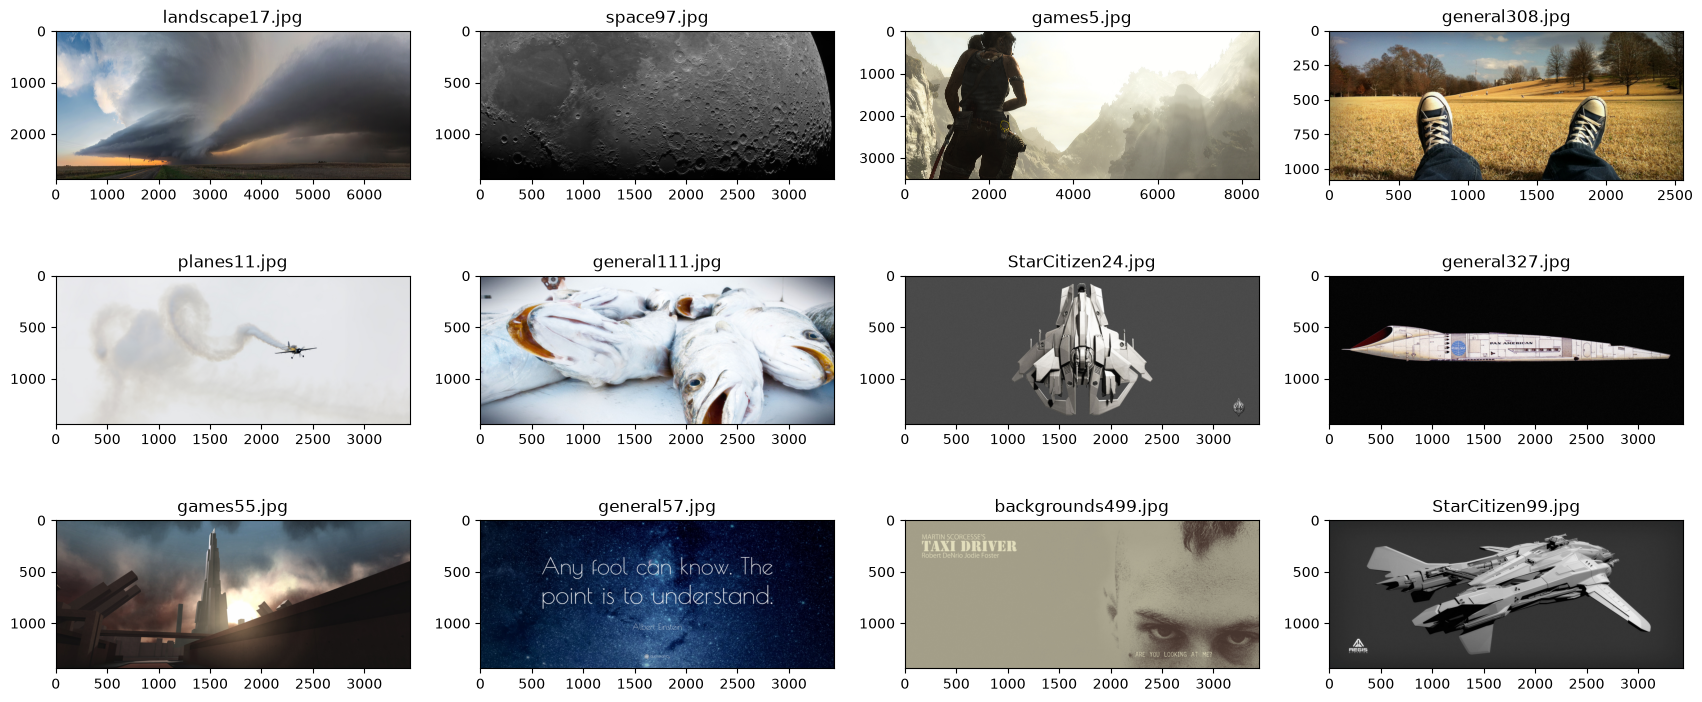

In [1]:
import os
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [21, 9]

# print dataset size and show random samples
root = './dataset'
src_root = './dataset/src' # source images, full-sized
filenames = os.listdir(src_root)

num_samples = len(filenames)
print("Dataset size: ", num_samples)

for i in range(12):
    # get random index
    idx = np.random.randint(0, num_samples)
    # load and show image
    img = Image.open(os.path.join(src_root, filenames[idx]))
    plt.subplot(3, 4, i+1), plt.imshow(img), plt.title(filenames[idx])

In [2]:
# gather and print stats
widths = []
heights = []
for name in filenames:
    path = os.path.join(src_root, name)
    img = Image.open(path)
    widths.append(img.width)
    heights.append(img.height)

print('Widths: ', np.min(widths), np.max(widths))
print('Heights: ', np.min(heights), np.max(heights))

from collections import Counter
width_stats = Counter(widths)
print(width_stats)

aspect_ratio = np.array(widths) / np.array(heights)
print('Aspect ratios: ', np.min(aspect_ratio), np.max(aspect_ratio))
print('Mean aspect ratio: ', np.mean(aspect_ratio), np.std(aspect_ratio))

Widths:  2560 14232
Heights:  1080 5961
Counter({3440: 1693, 6880: 123, 2560: 95, 5760: 11, 6000: 11, 4000: 11, 4256: 9, 3840: 7, 4288: 7, 7680: 6, 4500: 6, 8000: 6, 5120: 5, 5000: 4, 5616: 4, 10000: 4, 4928: 3, 6400: 3, 5184: 3, 7360: 3, 3439: 3, 3888: 3, 5440: 3, 6428: 3, 5226: 2, 5252: 2, 3437: 2, 5586: 2, 7900: 2, 3648: 2, 4872: 2, 4608: 2, 4096: 2, 4897: 2, 5567: 2, 4368: 2, 5476: 2, 7000: 2, 3438: 2, 5906: 2, 4816: 2, 4774: 2, 4752: 2, 4806: 2, 4495: 2, 4504: 2, 3200: 2, 7112: 2, 7698: 1, 5128: 1, 10250: 1, 5461: 1, 7826: 1, 6842: 1, 5878: 1, 4234: 1, 5228: 1, 3433: 1, 4554: 1, 6601: 1, 4961: 1, 5683: 1, 5527: 1, 5692: 1, 4999: 1, 4294: 1, 5042: 1, 4028: 1, 4099: 1, 4167: 1, 5087: 1, 5454: 1, 5180: 1, 12126: 1, 3113: 1, 5612: 1, 6444: 1, 4972: 1, 6260: 1, 5875: 1, 14232: 1, 2800: 1, 4550: 1, 8931: 1, 4695: 1, 9231: 1, 9779: 1, 4488: 1, 5917: 1, 4296: 1, 5976: 1, 3853: 1, 4029: 1, 5100: 1, 8192: 1, 9600: 1, 5284: 1, 4878: 1, 5472: 1, 3837: 1, 5968: 1, 8592: 1, 5347: 1, 5920: 1, 37

In [3]:
# create folders if necessary
for size in ['16', '8', '4', '2', '1']:
    dst_dir = os.path.join(root, size)
    if not os.path.exists(dst_dir):
        os.mkdir(dst_dir)

# create dataset with different image sizes: downsize the source images up to 16 times
for name in tqdm(filenames):
    path = os.path.join(src_root, name)
    
    # crop source images for their sizes to be divisible by 16
    dst_path = os.path.join(root, '16', name)
    img = Image.open(path).convert("RGB")
    img = img.crop((0, 0, (img.width // 16) * 16, (img.height // 16) * 16))
    img.save(dst_path)
    
    # create 4 folders with downsized images, each one is half the size of the previous
    for size in ['8', '4', '2', '1']:
        dst_path = os.path.join(root, size, name)
        img = img.resize((img.width // 2, img.height // 2), Image.LANCZOS) # best results for downsizing
        img.save(dst_path)

  0%|          | 0/2309 [00:00<?, ?it/s]

Minimum image size after downsizing: 160x67